In [ ]:

print("Hello, welcome to my first Data Analysis project!")

price = 800
quantity = 5
costs = 1500

revenue = price * quantity
profit = revenue - costs

print("Revenue:", revenue)
print("Profit:", profit)

import pandas as pd



Hello, welcome to my first Data Analysis project!
Revenue: 4000
Profit: 2500


In [ ]:

data = {
    "Product": ["Laptop", "Mouse", "Keyboard", "Monitor", "Headphones"],
    "Price": [1000, 25, 80, 300, 150],
    "Quantity": [3, 10, 5, 4, 6],
    "Category": ["Computers", "Accessories", "Accessories", "Screens", "Audio"]
}

df = pd.DataFrame(data)

df

df.head()
df.shape
df.columns
df.info()

df["Revenue"] = df["Price"] * df["Quantity"]

df

total_revenue = df["Revenue"].sum()

print("Total Revenue:", total_revenue)


print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])
print("Total Revenue:", df["Revenue"].sum())
print("Average Revenue:", df["Revenue"].mean())


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5 entries, 0 to 4
Data columns (total 4 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   Product   5 non-null      object
 1   Price     5 non-null      int64 
 2   Quantity  5 non-null      int64 
 3   Category  5 non-null      object
dtypes: int64(2), object(2)
memory usage: 292.0+ bytes
Total Revenue: 5750
Number of rows: 5
Number of columns: 5
Total Revenue: 5750
Average Revenue: 1150.0


In [14]:

import pandas as pd

url = "https://raw.githubusercontent.com/deepakorani/Supermarket-Sales-Kaggle-Dataset/main/supermarket_sales.csv"

df = pd.read_csv(url)

df.head()

print(df.shape)

print(df.columns.tolist())

df.info()

df.isnull().sum()

df.duplicated().sum()

df.describe()



# Afficher les 10 premières transactions
print(df.head(10))

# Voir les différentes catégories de produits
print(df["Product line"].unique())

# Calculer le total des ventes, taxes incluses
print(df["Total"].sum())

# Create a working copy of the original dataset
df_clean = df.copy()

# Display the dimensions
print(df_clean.shape)


# Count missing values in each column
missing_values = df_clean.isnull().sum()

print(missing_values)

total_missing = df_clean.isnull().sum().sum()

print("Total missing values:", total_missing)

# Count identical rows
duplicates = df_clean.duplicated().sum()

print("Duplicate rows:", duplicates)


# Count repeated invoice identifiers
duplicate_ids = df_clean["Invoice ID"].duplicated().sum()

print("Repeated Invoice IDs:", duplicate_ids)

df_clean.dtypes

# Convert Date column into datetime format
df_clean["Date"] = pd.to_datetime(
    df_clean["Date"],
    format="%m/%d/%Y",
    errors="coerce"
)

print(df_clean["Date"].head())


invalid_dates = df_clean["Date"].isna().sum()

print("Invalid dates:", invalid_dates)

print(df_clean[["Unit price", "Quantity", "Total"]].describe())
df_clean[["Unit price", "Quantity", "Total"]]

negative_prices = df_clean[df_clean["Unit price"] < 0]

print("Negative prices:", len(negative_prices))

invalid_quantities = df_clean[df_clean["Quantity"] <= 0]

print("Invalid quantities:", len(invalid_quantities))

# Calculate expected total including 5% tax
df_clean["Expected_Total"] = (
    df_clean["Unit price"]
    * df_clean["Quantity"]
    * 1.05
)

# Calculate difference from recorded total
df_clean["Total_Difference"] = abs(
    df_clean["Total"] - df_clean["Expected_Total"]
)

# Find potentially inconsistent transactions
suspicious_sales = df_clean[
    df_clean["Total_Difference"] > 0.01
]

print("Suspicious transactions:", len(suspicious_sales))

df_clean["Month"] = df_clean["Date"].dt.month

df_clean[["Date", "Month"]].head()

df_clean.to_csv(
    "supermarket_sales_cleaned.csv",
    index=False
)

print("Dataset saved successfully!")

import pandas as pd

# Check that our cleaned dataset exists
print(df_clean.shape)

# Display first 5 rows
df_clean.head()

total_sales = df_clean["Total"].sum()

print("Total Sales:", round(total_sales, 2))

total_transactions = len(df_clean)

print("Total Transactions:", total_transactions)

unique_transactions = df_clean["Invoice ID"].nunique()

print("Unique Transactions:", unique_transactions)

average_transaction = df_clean["Total"].mean()

print("Average Transaction:", round(average_transaction, 2))
average_transaction = total_sales / total_transactions

total_units = df_clean["Quantity"].sum()

print("Total Units Sold:", total_units)

sales_by_city = df_clean.groupby("City")["Total"].sum()

print(sales_by_city)

sales_by_category = (
    df_clean.groupby("Product line")["Total"]
    .sum()
    .sort_values(ascending=False)
)

print(sales_by_category)

df_clean.groupby("City")["Total"].sum()

city_summary = df_clean.groupby("City").agg(
    Total_Sales=("Total", "sum"),
    Average_Sale=("Total", "mean"),
    Transactions=("Invoice ID", "nunique"),
    Units_Sold=("Quantity", "sum")
)

print(city_summary)
Total_Sales=("Total", "sum")
Average_Sale=("Total", "mean")

monthly_sales = (
    df_clean.groupby("Month")["Total"]
    .sum()
    .sort_index()
)

print(monthly_sales)

# MAIN KPI REPORT

total_sales = df_clean["Total"].sum()
total_transactions = df_clean["Invoice ID"].nunique()
average_sale = df_clean["Total"].mean()
total_units = df_clean["Quantity"].sum()

print("===== SUPERMARKET SALES REPORT =====")

print("Total Sales:", round(total_sales, 2))
print("Transactions:", total_transactions)
print("Average Sale:", round(average_sale, 2))
print("Units Sold:", total_units)

print("\n===== SALES BY CITY =====")
print(
    df_clean.groupby("City")["Total"]
    .sum()
    .sort_values(ascending=False)
)

print("\n===== SALES BY CATEGORY =====")
print(
    df_clean.groupby("Product line")["Total"]
    .sum()
    .sort_values(ascending=False)
)


(1000, 17)
['Invoice ID', 'Branch', 'City', 'Customer type', 'Gender', 'Product line', 'Unit price', 'Quantity', 'Tax 5%', 'Total', 'Date', 'Time', 'Payment', 'cogs', 'gross margin percentage', 'gross income', 'Rating']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 17 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Invoice ID               1000 non-null   object 
 1   Branch                   1000 non-null   object 
 2   City                     1000 non-null   object 
 3   Customer type            1000 non-null   object 
 4   Gender                   1000 non-null   object 
 5   Product line             1000 non-null   object 
 6   Unit price               1000 non-null   float64
 7   Quantity                 1000 non-null   int64  
 8   Tax 5%                   1000 non-null   float64
 9   Total                    1000 non-null   float64
 10  Date                 

Product line
Food and beverages        56144.8440
Sports and travel         55122.8265
Electronic accessories    54337.5315
Fashion accessories       54305.8950
Home and lifestyle        53861.9130
Health and beauty         49193.7390
Name: Total, dtype: float64


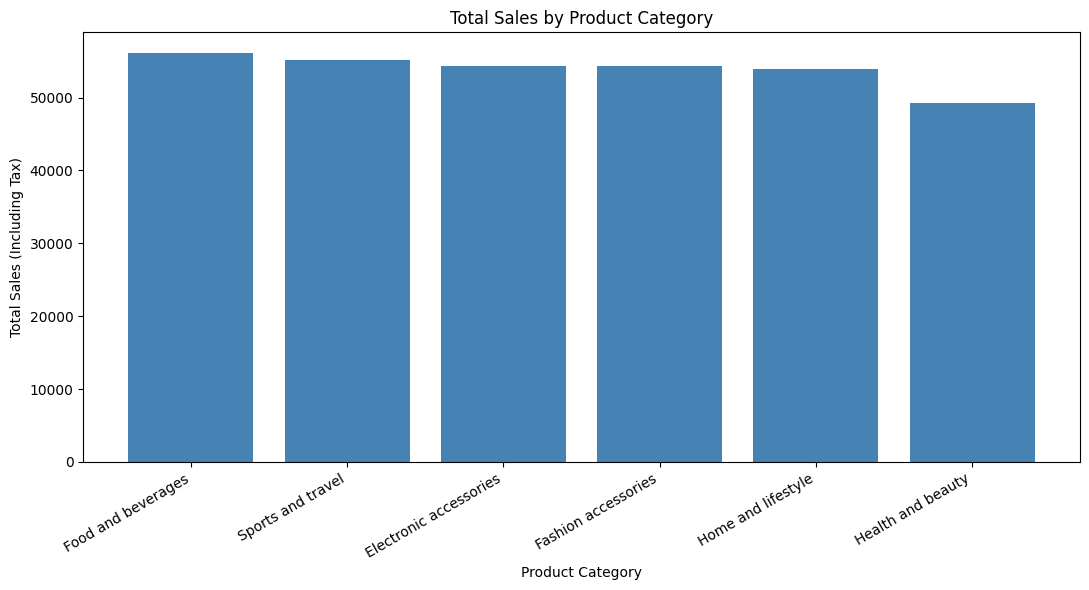

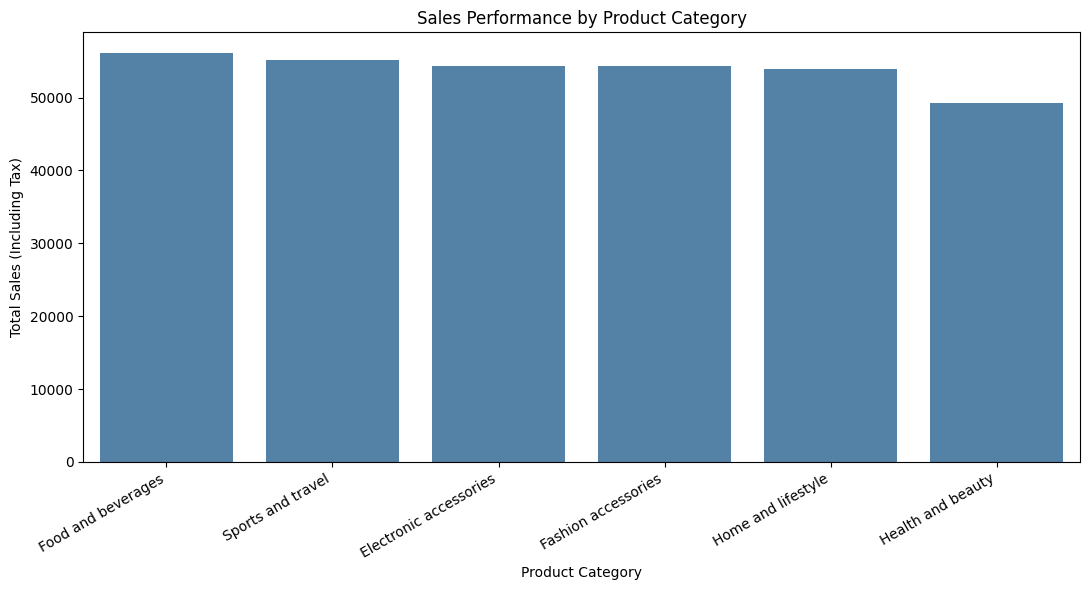

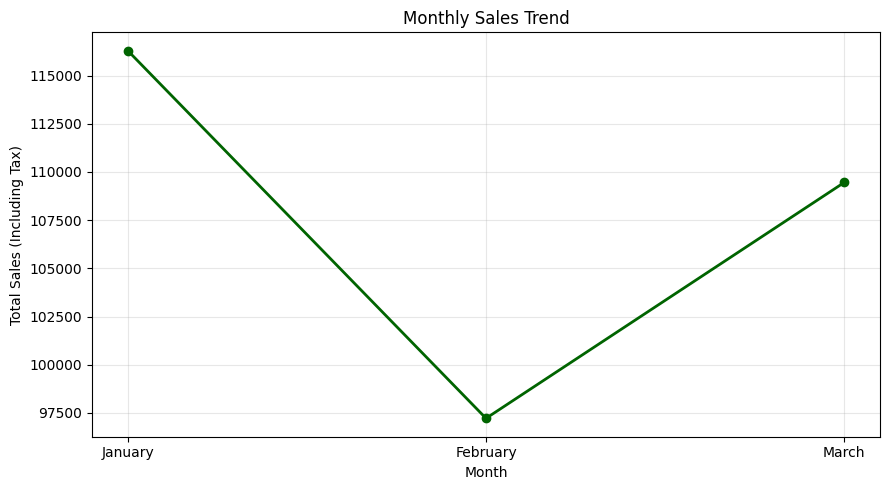

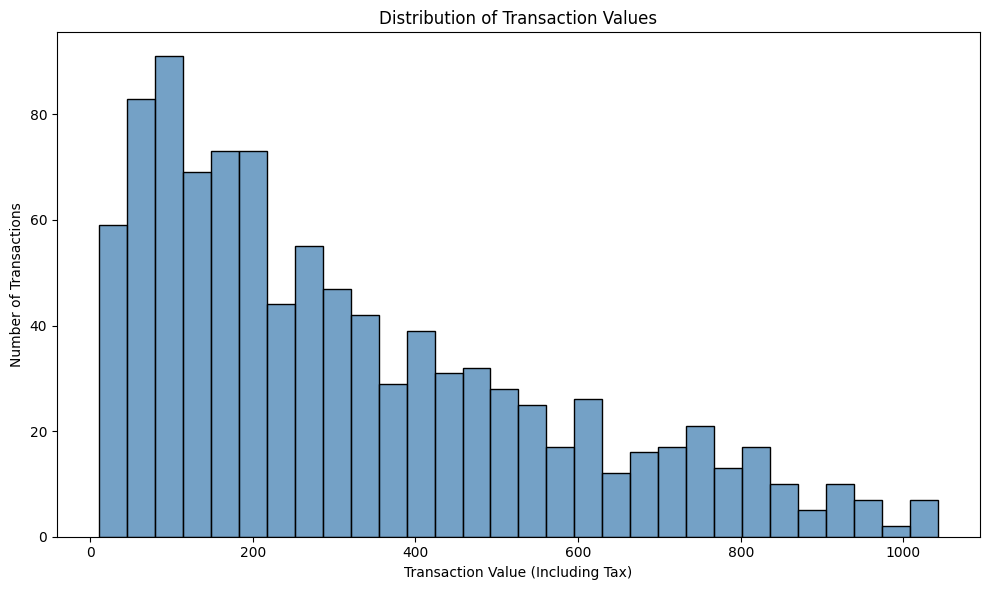

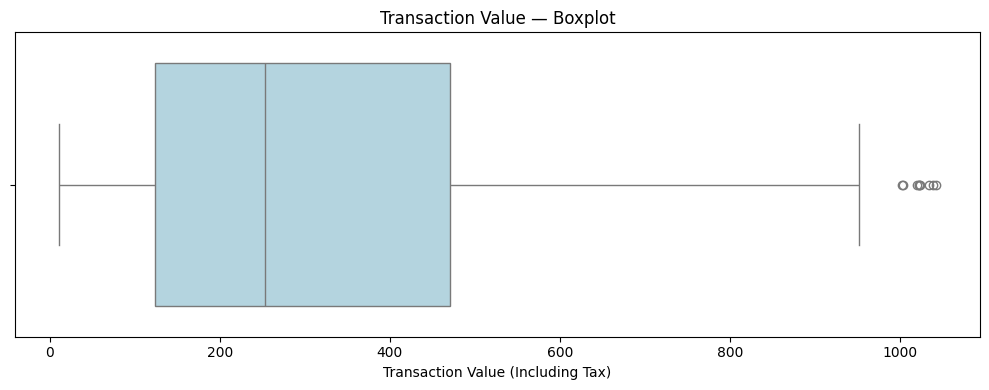

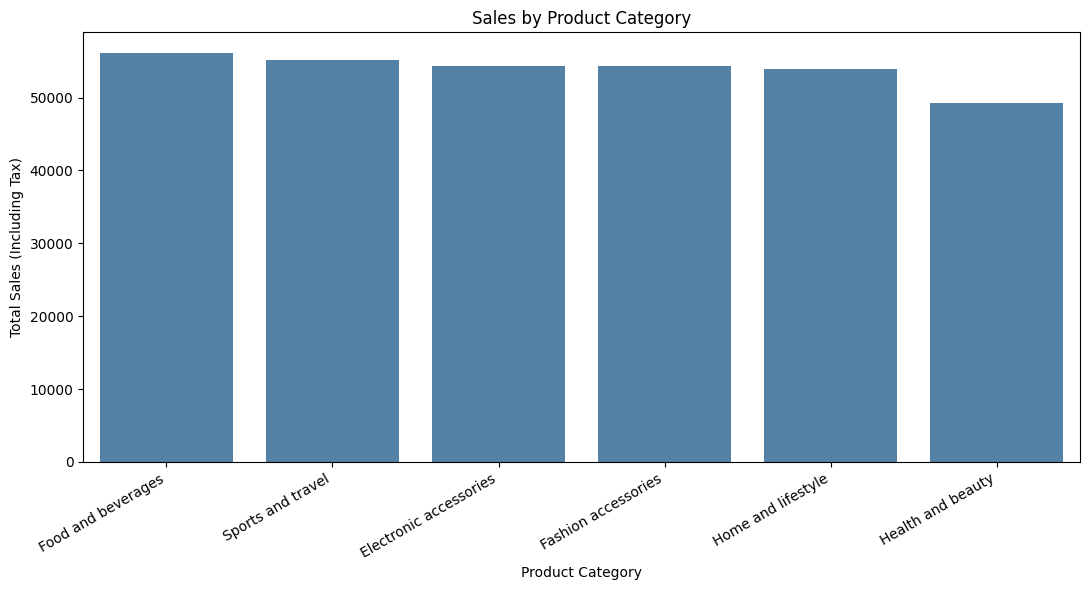

Median: 253.85
Standard deviation: 245.89
Minimum: 10.68
Maximum: 1042.65
EXECUTIVE SUMMARY
-----------------
The dataset contains 1,000 transactions.
Total sales reached 322,966.75.
The average transaction value was 322.97.
Naypyitaw generated the highest total sales.
Food and beverages was the leading product category.


'Total sales reached 322,966.75.'

In [29]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df_clean.head()

df_clean = pd.read_csv("supermarket_sales_cleaned.csv")

df_clean["Date"] = pd.to_datetime(
    df_clean["Date"]
)

df_clean.head()

category_sales = (
    df_clean.groupby("Product line")["Total"]
    .sum()
    .sort_values(ascending=False)
)

print(category_sales)

plt.figure(figsize=(11, 6))

plt.bar(
    category_sales.index,
    category_sales.values,
    color="steelblue"
)

plt.title("Total Sales by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Total Sales (Including Tax)")

plt.xticks(rotation=30, ha="right")

plt.tight_layout()
plt.show()

plt.figure(figsize=(11, 6))

sns.barplot(
    x=category_sales.index,
    y=category_sales.values,
    color="steelblue"
)

plt.title("Sales Performance by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Total Sales (Including Tax)")
plt.xticks(rotation=30, ha="right")

plt.tight_layout()
plt.show()

plt.figure(figsize=(9, 5))

plt.plot(
    monthly_sales.index,
    monthly_sales.values,
    marker="o",
    linewidth=2,
    color="darkgreen"
)

plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Sales (Including Tax)")

plt.xticks([1, 2, 3], ["January", "February", "March"])

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 6))

sns.histplot(
    data=df_clean,
    x="Total",
    bins=30,
    color="steelblue"
)

plt.title("Distribution of Transaction Values")
plt.xlabel("Transaction Value (Including Tax)")
plt.ylabel("Number of Transactions")

plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 4))

sns.boxplot(
    data=df_clean,
    x="Total",
    color="lightblue"
)

plt.title("Transaction Value — Boxplot")
plt.xlabel("Transaction Value (Including Tax)")

plt.tight_layout()
plt.show()

import os

# Create a folder for our figures
os.makedirs("figures", exist_ok=True)

plt.figure(figsize=(11, 6))

sns.barplot(
    x=category_sales.index,
    y=category_sales.values,
    color="steelblue"
)

plt.title("Sales by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Total Sales (Including Tax)")
plt.xticks(rotation=30, ha="right")

plt.tight_layout()

plt.savefig(
    "figures/sales_by_category.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Calculate transaction statistics
median_transaction = df_clean["Total"].median()
std_transaction = df_clean["Total"].std()
min_transaction = df_clean["Total"].min()
max_transaction = df_clean["Total"].max()

print("Median:", round(median_transaction, 2))
print("Standard deviation:", round(std_transaction, 2))
print("Minimum:", round(min_transaction, 2))
print("Maximum:", round(max_transaction, 2))


total_sales = df_clean["Total"].sum()
transactions = df_clean["Invoice ID"].nunique()
average_sale = df_clean["Total"].mean()

top_city = (
    df_clean.groupby("City")["Total"]
    .sum()
    .idxmax()
)

top_category = (
    df_clean.groupby("Product line")["Total"]
    .sum()
    .idxmax()
)

print("EXECUTIVE SUMMARY")
print("-----------------")

print(
    f"The dataset contains {transactions:,} transactions."
)

print(
    f"Total sales reached {total_sales:,.2f}."
)

print(
    f"The average transaction value was {average_sale:,.2f}."
)

print(
    f"{top_city} generated the highest total sales."
)

print(
    f"{top_category} was the leading product category."
)
f"Total sales reached {total_sales:,.2f}."


# Retail Sales Performance Analysis

## Project Overview

This project analyzes supermarket sales data using Python
and Pandas to identify business performance trends.

The analysis covers 1,000 transactions across three
branches from January to March 2019.

## Objectives

- Analyze total sales and transaction values.
- Compare sales performance across cities.
- Identify the highest-revenue product categories.
- Explore monthly sales trends.
- Provide data-driven business recommendations.

## Tools Used

- Python
- Pandas
- Matplotlib
- Seaborn
- Google Colab

## Data Source

Public Supermarket Sales dataset, originally published
on Kaggle and accessed through a GitHub CSV mirror.

## Methodology

1. Import and inspect the dataset.
2. Check data quality and identify anomalies.
3. Calculate key performance indicators.
4. Analyze sales by city, category, and month.
5. Create visualizations.
6. Interpret findings and document limitations.
